# Neural Networks: Class Practice
** CSCI 345 **

Work through this notebook. Run each cell with **Shift + Enter**.

- Cells marked **Exercise** have a `# TODO` for you to complete (replace each `...`).
- Cells marked **Think** ask you to write a short answer in the Markdown cell below them.
- Some cells say *"run after Exercise …"*: they use your answers, so finish that exercise first.

| Part | Topic |
|---|---|
| 1 | Activation functions |
| 2 | A forward pass by hand |
| 3 | Training the final bias with gradient descent (backpropagation) |
| 4 | Challenge: training two parameters with the chain rule |
| 5 | Neural networks in scikit-learn |

## 0. Setup
Run this cell first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BLUE, ORANGE, GREEN, PINK = "#1f6feb", "#d1620a", "#2a9d3c", "#c2185b"
dose_grid = np.linspace(0, 1, 200)       # doses from 0 to 1, for plotting curves
print("Ready! ")

Ready! 


## Part 1. Activation Functions

An activation function is just a math function: plug in $x$, get $y$.

| Name | Formula |
|---|---|
| ReLU | $\max(0, x)$ |
| SoftPlus | $\log(1 + e^x)$ (natural log) |
| Sigmoid | $\dfrac{1}{1 + e^{-x}}$ |

### ✏️ Exercise 1.1: write the three functions
Use NumPy so they work on whole arrays: `np.maximum`, `np.log`, `np.exp`.

In [3]:
def relu(x):
    return np.maximum(0,x)  

def softplus(x):
    return np.log(1 + np.exp(x))

def sigmoid(x):
    return 1/(1 + np.exp(-x))

# Checks: you should see 0.0, 5.0, about 2.25 and 0.5
print(relu(-3), relu(5), round(softplus(2.14), 2), sigmoid(0))

0 5 2.25 0.5


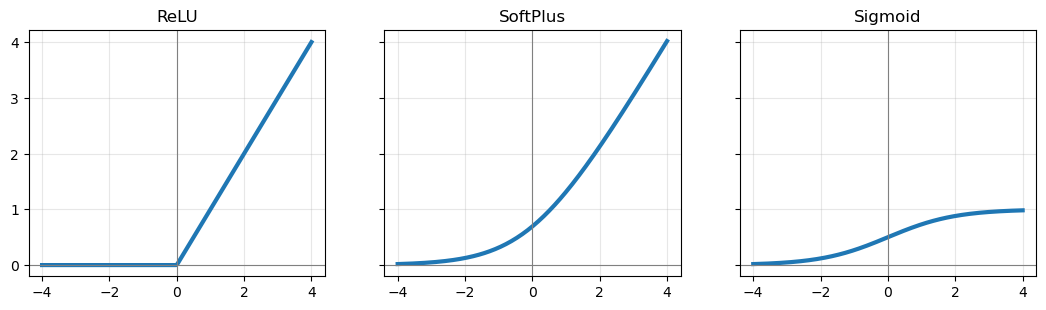

In [4]:
# Plot them (run after Exercise 1.1)
x = np.linspace(-4, 4, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, f, name in zip(axes, [relu, softplus, sigmoid], ["ReLU", "SoftPlus", "Sigmoid"]):
    ax.plot(x, f(x), lw=3)
    ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(name); ax.grid(alpha=0.3)
plt.show()

### 🤔 Think 1.2
What would a network compute if it had **no** activation functions, only multiplying by weights and adding biases (even with many layers)?

Your answer: It would only compute straight lines.

## Part 2. A Forward Pass by Hand

This is the network from the lecture:

```
             × -34.4  + 2.14 → [SoftPlus] → × -1.30  (blue)
Dose  ──<                                              >── Sum + (-0.58) → Effectiveness
             × -2.52  + 1.29 → [SoftPlus] → ×  2.28  (orange)
```

In [5]:
# The trained parameters (weights and biases) from the lecture
w1, b1, w3 = -34.4, 2.14, -1.30     # top hidden node
w2, b2, w4 = -2.52, 1.29,  2.28     # bottom hidden node
final_bias = -0.58

### ✏️ Exercise 2.1: code the forward pass
Each hidden node does: **multiply** the dose by its weight, **add** its bias, apply **SoftPlus**, then **multiply** by its outgoing weight.

In [15]:
def blue_curve(dose):
    return softplus((dose * w1) + b1) * w3           # TODO: top node, using w1, b1, w3

def orange_curve(dose):
    return softplus(dose*w2 + b2) * w4           # TODO: bottom node, using w2, b2, w4

def predict(dose, fb=final_bias):
    return orange_curve(dose) + blue_curve(dose) + fb           # TODO: blue + orange + the final bias fb

# Checks: about 0.0, 1.0 and 0.0
for d in [0, 0.5, 1]:
    print(f"dose = {d}:  blue = {blue_curve(d):6.2f}   orange = {orange_curve(d):5.2f}   prediction = {predict(d):5.2f}")

dose = 0:  blue =  -2.93   orange =  3.50   prediction = -0.01
dose = 0.5:  blue =  -0.00   orange =  1.61   prediction =  1.03
dose = 1:  blue =  -0.00   orange =  0.58   prediction =  0.00


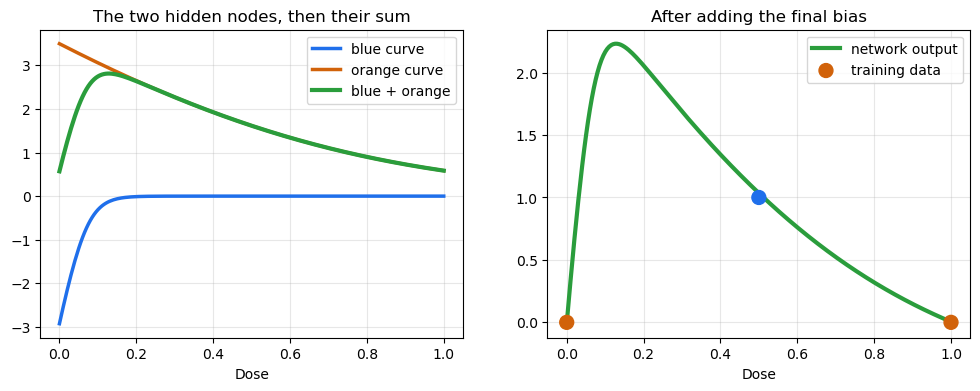

In [7]:
# Rebuild the lecture's pictures (run after Exercise 2.1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dose_grid, blue_curve(dose_grid), color=BLUE, lw=2.5, label="blue curve")
axes[0].plot(dose_grid, orange_curve(dose_grid), color=ORANGE, lw=2.5, label="orange curve")
axes[0].plot(dose_grid, blue_curve(dose_grid) + orange_curve(dose_grid), color=GREEN, lw=3, label="blue + orange")
axes[0].legend(); axes[0].set_title("The two hidden nodes, then their sum")

axes[1].plot(dose_grid, predict(dose_grid), color=GREEN, lw=3, label="network output")
axes[1].scatter([0, 0.5, 1], [0, 1, 0], s=100, c=[ORANGE, BLUE, ORANGE], zorder=3, label="training data")
axes[1].legend(); axes[1].set_title("After adding the final bias")
for ax in axes:
    ax.set_xlabel("Dose"); ax.grid(alpha=0.3)
plt.show()

### ✏️ Exercise 2.2: change a weight and watch the shape change
Each weight and bias **stretches, flips or shifts** a piece of the curve.
Try a few values for `new_w1` (for example `-5`, `-15`, `-60`) and `new_b2` (for example `0`, `3`), then rerun the cell.

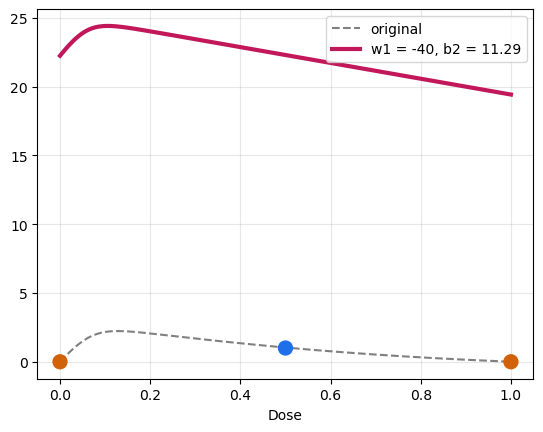

In [12]:
new_w1 = -40    # TODO: try different values (the trained value is -34.4)
new_b2 = 11.29    # TODO: try different values (the trained value is 1.29)

custom = softplus(new_w1 * dose_grid + b1) * w3 + softplus(w2 * dose_grid + new_b2) * w4 + final_bias
plt.plot(dose_grid, predict(dose_grid), color="grey", ls="--", label="original")
plt.plot(dose_grid, custom, color=PINK, lw=3, label=f"w1 = {new_w1}, b2 = {new_b2}")
plt.scatter([0, 0.5, 1], [0, 1, 0], s=100, c=[ORANGE, BLUE, ORANGE], zorder=3)
plt.legend(); plt.grid(alpha=0.3); plt.xlabel("Dose")
plt.show()

### 🤔 Think 2.3
Look at the output between doses 0 and 0.5. There's a big **bump** even though no training point is there. Why can the network do this, and why might that be a problem?

*Your answer:* The network can do this because it is only evaluated where there is a point, thus there is no loss for the big spike. This might be a problem because new data may contain a point at that spike, causing a large error.

## Part 3. Training the Final Bias (Backpropagation)

Pretend we know every parameter **except the final bias**. Let's learn it from the 3 training points.

$$\text{SSR} = \sum_i (\text{Observed}_i - \text{Predicted}_i)^2 \qquad\qquad \frac{d\,\text{SSR}}{d\,\text{Final Bias}} = \sum_i -2\,(\text{Observed}_i - \text{Predicted}_i) \times 1$$

In [13]:
doses    = np.array([0.0, 0.5, 1.0])
observed = np.array([0.0, 1.0, 0.0])

### ✏️ Exercise 3.1: the SSR and its derivative
Both functions take a value for the final bias `fb` and use `predict(doses, fb)`.

In [17]:
def ssr(fb):
    predicted = predict(doses, fb)
    return np.sum((predicted - observed)**2)          # TODO: sum of squared residuals

def d_ssr(fb):
    predicted = predict(doses, fb)
    return np.sum(-2*(observed- predicted))          # TODO: derivative of the SSR with respect to the final bias

# Checks: with fb = 0 you should get SSR ≈ 1.04 and derivative ≈ 3.54
print("SSR at 0:       ", round(ssr(0.0), 2))
print("Derivative at 0:", round(d_ssr(0.0), 2))

SSR at 0:        1.04
Derivative at 0: 3.54


### ✏️ Exercise 3.2: gradient descent
Repeat: compute the derivative, then **step size = derivative × learning rate**, then **new bias = old bias − step size**.
Stop when the step size is tiny (`abs(step) < 0.001`) or after `max_steps`.

In [18]:
def gradient_descent(learning_rate=0.1, start=0.0, max_steps=100):
    fb = start
    history = [fb]
    for step_number in range(max_steps):
        derivative = d_ssr(fb)
        step = derivative * learning_rate
        fb = fb - step
        history.append(fb)
        if abs(step) < 0.001:
            break
    return np.array(history)

history = gradient_descent(learning_rate=0.1)
for i, fb in enumerate(history):
    print(f"step {i}: final bias = {fb:6.3f}   SSR = {ssr(fb):.4f}")

step 0: final bias =  0.000   SSR = 1.0436
step 1: final bias = -0.354   SSR = 0.1679
step 2: final bias = -0.495   SSR = 0.0278
step 3: final bias = -0.552   SSR = 0.0054
step 4: final bias = -0.574   SSR = 0.0018
step 5: final bias = -0.583   SSR = 0.0012
step 6: final bias = -0.587   SSR = 0.0011
step 7: final bias = -0.589   SSR = 0.0011
step 8: final bias = -0.589   SSR = 0.0011


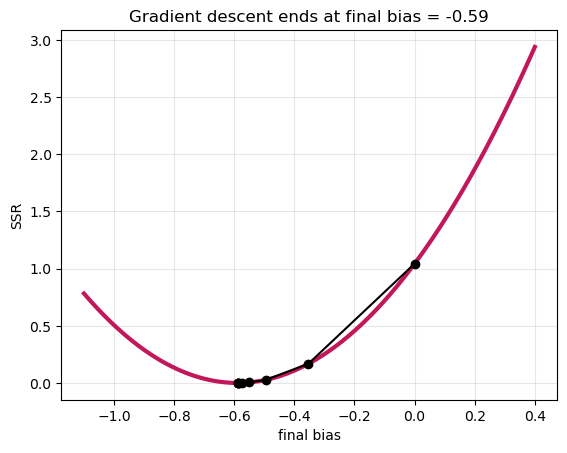

In [19]:
# See the path on the SSR curve (run after Exercise 3.2)
fbs = np.linspace(-1.1, 0.4, 200)
plt.plot(fbs, [ssr(f) for f in fbs], color=PINK, lw=3)
plt.plot(history, [ssr(f) for f in history], "ko-", ms=6)
plt.xlabel("final bias"); plt.ylabel("SSR"); plt.grid(alpha=0.3)
plt.title(f"Gradient descent ends at final bias = {history[-1]:.2f}")
plt.show()

### ✏️ Exercise 3.3: what does the learning rate do?
Run gradient descent with learning rates **0.01, 0.1, 0.3 and 0.4** (use `max_steps=30`) and plot the final bias after each step.

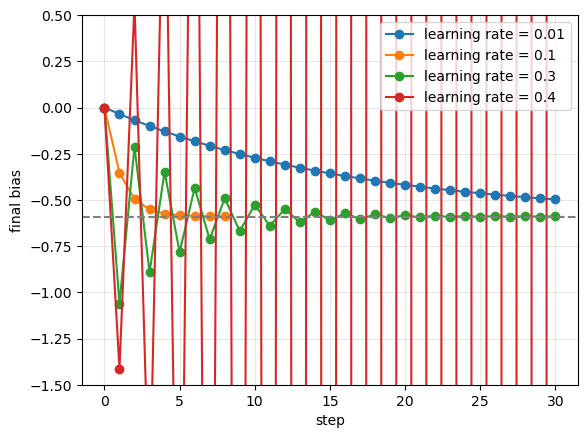

In [20]:
for lr in [0.01, 0.1, 0.3, 0.4]:
    path = gradient_descent(lr, max_steps=30)
    plt.plot(path, "o-", label=f"learning rate = {lr}")
plt.axhline(-0.59, color="grey", ls="--")
plt.ylim(-1.5, 0.5); plt.xlabel("step"); plt.ylabel("final bias"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### 🤔 Think 3.4
1. Which learning rate is **too slow**? Which one **bounces** back and forth? Which one **blows up**?
2. Why do the steps get smaller by themselves as we get close to the minimum, even though the learning rate stays the same?

*Your answer:*
1. The learning rate of 0.01 is too slow. The learning rates of 0.4 and 0.3 both bounce, but 0.4 blows up in its bounces whereas 0.3 eventually bounces to the correct answer.
2.The step size is proportional to the error size. As we get closer to the minimum, the error size decreases, thus the step size decreases.

## Part 4. ⭐ Challenge: Train Two Parameters at Once

Now pretend we also don't know $w_3$ (the **−1.30** on the top node's outgoing arrow). Start **both** $w_3$ and the final bias at **0**.

By the chain rule:

$$\frac{d\,\text{SSR}}{d\,w_3} = \sum_i -2\,(\text{Observed}_i - \text{Predicted}_i) \times \frac{d\,\text{Predicted}_i}{d\,w_3}
\qquad\text{where}\qquad
\frac{d\,\text{Predicted}_i}{d\,w_3} = \text{SoftPlus}(w_1 \cdot \text{dose}_i + b_1)$$

*(Because Predicted = SoftPlus(…) × $w_3$ + orange + final bias, and the derivative of $a \times w_3$ with respect to $w_3$ is $a$.)*

In [33]:
top_activation = softplus(w1 * doses + b1)       # SoftPlus output of the top node for each training dose

def predict_2(w3_value, fb):
    return top_activation * w3_value + orange_curve(doses) + fb

w3_value, fb = 0.0, 0.0
learning_rate = 0.0001
for step_number in range(200000):
    residual = observed - predict_2(w3_value, fb)
    grad_w3 = np.sum([-2*(residual[i] * softplus(w1 * doses[i] + b1)) for i in range(len(doses))])              # TODO: derivative of SSR with respect to w3
    grad_fb = np.sum(-2 * residual)              # TODO: derivative of SSR with respect to the final bias
    w3_value = w3_value - learning_rate * grad_w3             # TODO: gradient descent update
    fb = fb - learning_rate*grad_fb                   # TODO: gradient descent update


print("Residual with Learned values: ", np.sum(residual**2))
print("Residual from Lecture: ", np.sum((observed - predict_2(-1.30, -0.58))**2))
print(f"learned w3 = {w3_value:.2f} (lecture: -1.30),  final bias = {fb:.2f} (lecture: -0.58)")

Residual with Learned values:  0.00045599077147533433
Residual from Lecture:  0.001355728234088509
learned w3 = -1.29 (lecture: -1.30),  final bias = -0.60 (lecture: -0.58)


This is **backpropagation**: a real network does exactly this for **every** weight and bias, using the chain rule from the output back toward the input.

## Part 5. Neural Networks in scikit-learn

scikit-learn's **MLP** (multi-layer perceptron) does the forward pass, backpropagation and gradient descent for us.

### 5.1 Regression: fit the drug data
More data this time: low, medium and high doses.

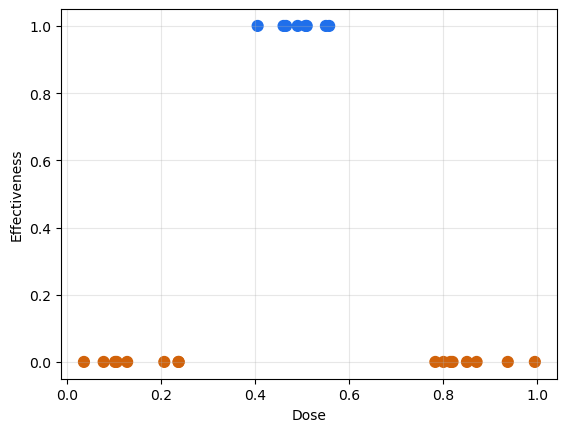

In [34]:
rng = np.random.default_rng(1)
dose_data = np.r_[rng.uniform(0, 0.25, 8), rng.uniform(0.4, 0.6, 8), rng.uniform(0.75, 1, 8)]
effect    = np.r_[np.zeros(8), np.ones(8), np.zeros(8)]

plt.scatter(dose_data, effect, c=[BLUE if e else ORANGE for e in effect], s=60)
plt.xlabel("Dose"); plt.ylabel("Effectiveness"); plt.grid(alpha=0.3)
plt.show()

### ✏️ Exercise 5.1: how many hidden nodes do we need?
Fit an `MLPRegressor` with **1**, **2** and **10** hidden nodes (one hidden layer) and compare the curves.
Use `hidden_layer_sizes=(n,)`, `activation="tanh"`, `solver="lbfgs"`, `max_iter=5000`, `random_state=0`.

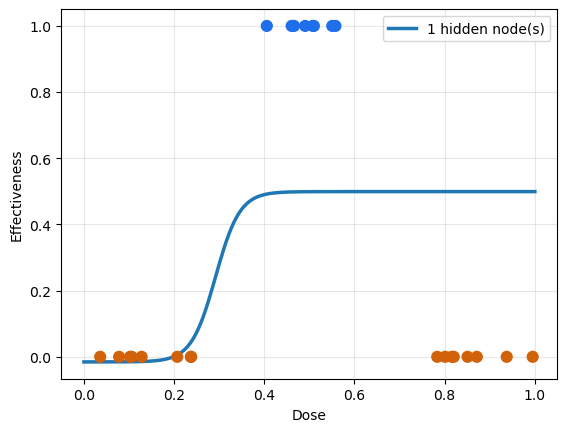

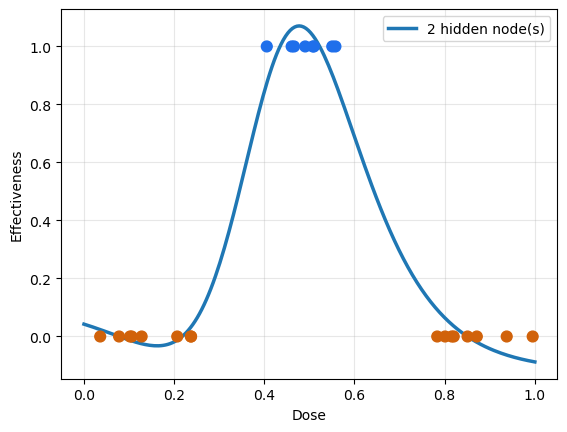

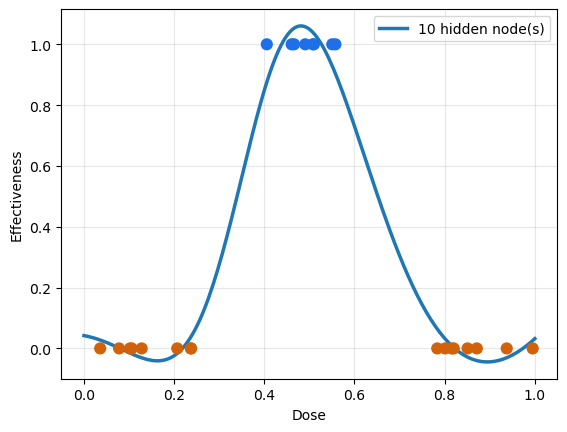

In [40]:

for n in [1, 2, 10]:
    mlp = MLPRegressor(activation= 'tanh', hidden_layer_sizes= (n), solver= 'lbfgs', max_iter=5000, random_state=0)     # TODO: create and fit the MLPRegressor (remember: X must be 2-D → dose_data.reshape(-1, 1))
    mlp.fit(dose_data.reshape(-1,1), effect)
    plt.scatter(dose_data, effect, c=[BLUE if e else ORANGE for e in effect], s=60, zorder=3)
    plt.plot(dose_grid, mlp.predict(dose_grid.reshape(-1, 1)), lw=2.5, label=f"{n} hidden node(s)")
    plt.legend(); plt.xlabel("Dose"); plt.ylabel("Effectiveness"); plt.grid(alpha=0.3)
    plt.show()

### 🤔 Think 5.2
Why can't **1** hidden node fit this data? *(Hint: what shape does one tanh curve have?)*

*Your answer:* Because tanh does'nt have enough curves to match the data.

### 5.3 Classification: neural network vs. logistic regression

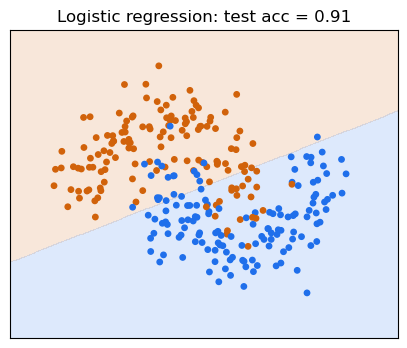

In [41]:
X, y = make_moons(n_samples=400, noise=0.25, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)


def plot_boundary(model, ax, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.15, colors=[ORANGE, BLUE], levels=[-0.5, 0.5, 1.5])
    ax.scatter(X_train[:, 0], X_train[:, 1], c=[BLUE if t else ORANGE for t in y_train], s=15)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])


logreg = LogisticRegression().fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(5, 4))
plot_boundary(logreg, ax, f"Logistic regression: test acc = {logreg.score(X_test, y_test):.2f}")
plt.show()

### ✏️ Exercise 5.3: try different network sizes
For each architecture below, build a pipeline `StandardScaler()` → `MLPClassifier(hidden_layer_sizes=..., learning_rate_init=0.01, max_iter=3000, random_state=0)`, fit it, and show the boundary with its train and test accuracy.

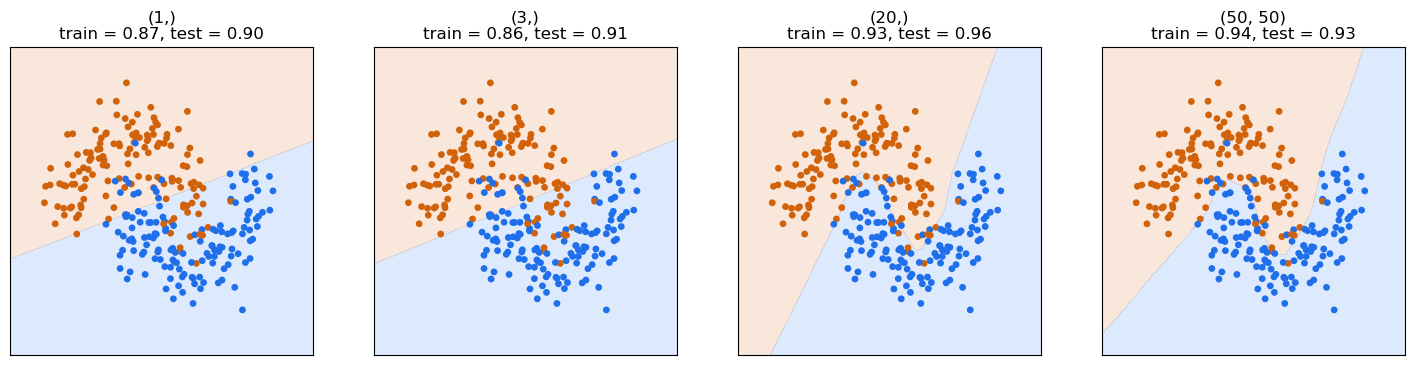

In [ ]:
architectures = [(1,), (3,), (20,), (50, 50)]
fig, axes = plt.subplots(1, len(architectures), figsize=(18, 4))
for ax, arch in zip(axes, architectures):
    model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes= arch, learning_rate_init=0.01, max_iter=3000, random_state=0)) 
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)                               
    test_acc = model.score(X_test, y_test)
    plot_boundary(model, ax, f"{arch}\ntrain = {train_acc:.2f}, test = {test_acc:.2f}")
plt.show()

### 🤔 Think 5.4
1. Which architecture behaves most like logistic regression? Why?
2. Does the **biggest** network always give the best **test** accuracy?
3. Give one reason you might still choose **logistic regression** over a neural network.

*Your answer:* 
1. The architecture with only one hidden layer functions most like regression because it can only produce a line.
2. It does not. Big networks tend to overfit the data.
3. Logistic regression is likely a much faster model to run as there are fewer paramaters to optimize compared to a neural network.

---
## ✅ Summary
- A neural network = **weights** (×), **biases** (+) and **activation functions**, combined to fit squiggles.
- A **forward pass** computes the prediction; the **SSR** (or another loss) measures the error.
- **Backpropagation** = the **chain rule** to get derivatives + **gradient descent** to update the parameters.
- The **learning rate** matters: too small is slow, too large bounces or blows up.
- More hidden nodes/layers make the model more **flexible**, but not always better on **new** data.